# ✈️ Airline Flight Delays Analysis
**Mini Project – B.Tech 1st Year**  
**Submitted by:** Lakshya Tripathi  
**Admission No.:** 2026B01010860
**Github repo:** https://github.com/tripathilakshya456-pixel/WEB-D-CSE-8.git
**Tools used:** Python • NumPy • Pandas • Matplotlib

---
### 🎯 What will this notebook do?
1. Create a flight dataset (5,000 flights)
2. Explore and clean the data
3. Create new useful columns
4. Answer questions like *Which airline is most delayed? Which time of day is worst? Which season has most delays?*
5. Draw simple charts
6. Write the final conclusion



## Step 1: Import the Libraries
`numpy` is used for numbers/arrays, `pandas` for tables (DataFrames), and `matplotlib` for charts.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)   # show all columns when printing
print("Libraries imported successfully!")
print("NumPy version :", np.__version__)
print("Pandas version:", pd.__version__)

Libraries imported successfully!
NumPy version : 2.4.6
Pandas version: 2.2.3


## Step 2: Create the Flight Dataset
Real airline data is very large, so for this beginner project we **generate a realistic sample dataset** using NumPy.  
`np.random.seed(42)` makes sure we get the **same data every time** we run the notebook.

> 💡 *Want to use a real dataset?* Upload a CSV file to Colab and use `df = pd.read_csv('your_file.csv')` instead of this step.
> You may need to rename the columns to match the ones used below.

In [33]:
np.random.seed(42)          # same random numbers every time
n = 5000                    # number of flights

airlines = ['SkyJet', 'AirNova', 'BlueWing', 'IndoAir', 'FlyHigh', 'CloudLine']
cities   = ['Delhi', 'Mumbai', 'Bengaluru', 'Chennai', 'Kolkata', 'Hyderabad']
days     = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

# ---- Basic flight information ----
df = pd.DataFrame({
    'Flight_ID'      : np.arange(1001, 1001 + n),
    'Airline'        : np.random.choice(airlines, n),
    'Origin'         : np.random.choice(cities, n),
    'Month'          : np.random.randint(1, 13, n),
    'Day_of_Week'    : np.random.choice(days, n),
    'Scheduled_Hour' : np.random.randint(5, 24, n),      # 5 AM to 11 PM
    'Distance_km'    : np.random.randint(300, 2500, n),
})

# ---- Create delay values (in minutes) ----
# Delay depends on: evening rush, bad-weather months, airline and origin airport
base_delay     = np.random.exponential(scale=8, size=n)
evening_effect = np.where(df['Scheduled_Hour'] >= 17, 10, 0)
month_effect   = np.where(df['Month'].isin([6, 7, 8, 9]), 6, 0) + np.where(df['Month'].isin([12, 1]), 9, 0)
airline_effect = df['Airline'].map({'SkyJet': 0, 'AirNova': 3, 'BlueWing': 6, 'IndoAir': -2, 'FlyHigh': 9, 'CloudLine': 2})
origin_effect  = df['Origin'].map({'Delhi': 8, 'Mumbai': 6, 'Bengaluru': 2, 'Chennai': 1, 'Kolkata': 3, 'Hyderabad': 0})
noise          = np.random.normal(0, 6, n)

delay = base_delay + evening_effect + month_effect + airline_effect + origin_effect + noise - 8
df['Departure_Delay_min'] = np.clip(delay, -15, None).round(0)   # negative = left early

# ---- Reasons for delay ----
reasons = np.random.choice(['Weather', 'Air Traffic', 'Technical Issue', 'Crew Delay', 'Late Aircraft'],
                           n, p=[0.25, 0.25, 0.15, 0.10, 0.25])
df['Delay_Reason'] = np.where(df['Departure_Delay_min'] > 15, reasons, 'No Delay')

# ---- Cancelled flights (about 2%) have no delay value ----
df['Cancelled'] = np.random.choice([0, 1], n, p=[0.98, 0.02])
df.loc[df['Cancelled'] == 1, 'Departure_Delay_min'] = np.nan
df.loc[df['Cancelled'] == 1, 'Delay_Reason'] = 'Cancelled'

# ---- Add a few data-entry problems on purpose (so we can practise cleaning) ----
missing_idx = np.random.choice(df.index[df['Cancelled'] == 0], 75, replace=False)
df.loc[missing_idx, 'Departure_Delay_min'] = np.nan                       # missing values
df = pd.concat([df, df.sample(30, random_state=1)], ignore_index=True)    # duplicate rows

print("Dataset created! Shape (rows, columns):", df.shape)

Dataset created! Shape (rows, columns): (5030, 10)


## Step 3: Explore the Data (First Look)

In [34]:
print("First 5 rows:")
df.head()

First 5 rows:


,Flight_ID,Airline,Origin,Month,Day_of_Week,Scheduled_Hour,Distance_km,Departure_Delay_min,Delay_Reason,Cancelled
0,1001,IndoAir,Chennai,9,Wed,20,1564,NaN,Cancelled,1
1,1002,FlyHigh,Delhi,8,Tue,8,455,19.0,Late Aircraft,0
2,1003,BlueWing,Chennai,2,Fri,12,651,NaN,Cancelled,1
3,1004,FlyHigh,Chennai,8,Mon,6,343,9.0,No Delay,0
4,1005,FlyHigh,Chennai,4,Tue,18,437,18.0,Late Aircraft,0


In [35]:
print("Last 5 rows:")
df.tail()

Last 5 rows:


,Flight_ID,Airline,Origin,Month,Day_of_Week,Scheduled_Hour,Distance_km,Departure_Delay_min,Delay_Reason,Cancelled
5025,2133,BlueWing,Hyderabad,3,Sun,20,1439,NaN,Late Aircraft,0
5026,5704,CloudLine,Bengaluru,2,Mon,14,1900,6.0,No Delay,0
5027,5495,CloudLine,Chennai,1,Tue,11,670,NaN,Cancelled,1
5028,3776,FlyHigh,Chennai,4,Sun,13,560,26.0,Technical Issue,0
5029,4186,BlueWing,Bengaluru,8,Sat,13,1166,13.0,No Delay,0


In [36]:
print("Number of rows and columns:", df.shape)
print()
df.info()          # column names, data types, non-null counts

Number of rows and columns: (5030, 10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Flight_ID            5030 non-null   int64  
 1   Airline              5030 non-null   object 
 2   Origin               5030 non-null   object 
 3   Month                5030 non-null   int64  
 4   Day_of_Week          5030 non-null   object 
 5   Scheduled_Hour       5030 non-null   int64  
 6   Distance_km          5030 non-null   int64  
 7   Departure_Delay_min  4836 non-null   float64
 8   Delay_Reason         5030 non-null   object 
 9   Cancelled            5030 non-null   int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 393.1+ KB


In [37]:
# Summary statistics of numeric columns
df.describe().round(2)

,Flight_ID,Month,Scheduled_Hour,Distance_km,Departure_Delay_min,Cancelled
count,5030.00,5030.00,5030.00,5030.00,4836.00,5030.00
mean,3502.48,6.54,14.10,1414.06,13.78,0.02
std,1442.75,3.47,5.49,636.93,12.55,0.15
min,1001.00,1.00,5.00,300.00,-15.00,0.00
25%,2252.25,4.00,9.00,860.00,5.00,0.00
50%,3504.50,7.00,14.00,1416.00,13.00,0.00
75%,4752.75,10.00,19.00,1965.00,21.00,0.00
max,6000.00,12.00,23.00,2499.00,81.00,1.00


In [38]:
# Check missing values in every column
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Flight_ID                0
Airline                  0
Origin                   0
Month                    0
Day_of_Week              0
Scheduled_Hour           0
Distance_km              0
Departure_Delay_min    194
Delay_Reason             0
Cancelled                0
dtype: int64

Duplicate rows: 30


## Step 4: Clean the Data
Cleaning steps:
1. Remove **duplicate** rows  
2. Study **cancelled** flights separately (they have no delay value)  
3. Fill the remaining **missing delay values** with the median

In [39]:
# 1. Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", before - len(df))
print("Rows now          :", len(df))

Duplicates removed: 30
Rows now          : 5000


In [40]:
# 2. Cancelled flights
cancel_rate = df['Cancelled'].mean() * 100
print(f"Overall cancellation rate: {cancel_rate:.2f}%")
print()
print("Cancellation rate by airline (%):")
print((df.groupby('Airline')['Cancelled'].mean() * 100).round(2).sort_values(ascending=False))

# Keep only flights that actually operated for the delay analysis
df_flown = df[df['Cancelled'] == 0].copy()
print()
print("Flights that operated:", len(df_flown))

Overall cancellation rate: 2.34%

Cancellation rate by airline (%):
Airline
AirNova      2.86
FlyHigh      2.70
CloudLine    2.56
IndoAir      2.38
BlueWing     1.97
SkyJet       1.61
Name: Cancelled, dtype: float64

Flights that operated: 4883


In [41]:
# 3. Fill missing delays with the MEDIAN (median is not affected by extreme values)
median_delay = df_flown['Departure_Delay_min'].median()
print("Missing delays before:", df_flown['Departure_Delay_min'].isnull().sum())

df_flown['Departure_Delay_min'] = df_flown['Departure_Delay_min'].fillna(median_delay)
# Delay_Reason must also be updated for the filled rows
df_flown['Delay_Reason'] = np.where(df_flown['Departure_Delay_min'] > 15,
                                    df_flown['Delay_Reason'].replace('No Delay', 'Unknown'),
                                    'No Delay')

print("Missing delays after :", df_flown['Departure_Delay_min'].isnull().sum())
print("Median delay used    :", median_delay, "minutes")

Missing delays before: 75
Missing delays after : 0
Median delay used    : 13.0 minutes


## Step 5: Create New Columns (Feature Engineering)
- **Is_Delayed** → 1 if delay is more than 15 minutes (this is the standard airline rule), else 0  
- **Delay_Category** → groups delays into levels using `pd.cut()`  
- **Time_of_Day** → Morning / Afternoon / Evening / Night  
- **Season** → Winter / Summer / Monsoon / Post-Monsoon using `np.select()`

In [42]:
# 1. Delayed or not (np.where works like an IF-ELSE for a whole column)
df_flown['Is_Delayed'] = np.where(df_flown['Departure_Delay_min'] > 15, 1, 0)

# 2. Delay category
df_flown['Delay_Category'] = pd.cut(df_flown['Departure_Delay_min'],
                                    bins=[-np.inf, 0, 15, 60, np.inf],
                                    labels=['Early/On Time', 'Slight (1-15)', 'Moderate (16-60)', 'Long (>60)'])

# 3. Time of day
df_flown['Time_of_Day'] = pd.cut(df_flown['Scheduled_Hour'],
                                 bins=[4, 11, 16, 20, 23],
                                 labels=['Morning (5-11)', 'Afternoon (12-16)', 'Evening (17-20)', 'Night (21-23)'])

# 4. Season
conditions = [df_flown['Month'].isin([12, 1, 2]),
              df_flown['Month'].isin([3, 4, 5]),
              df_flown['Month'].isin([6, 7, 8, 9])]
choices    = ['Winter', 'Summer', 'Monsoon']
df_flown['Season'] = np.select(conditions, choices, default='Post-Monsoon')

df_flown[['Flight_ID', 'Airline', 'Departure_Delay_min', 'Is_Delayed', 'Delay_Category', 'Time_of_Day', 'Season']].head(10)

,Flight_ID,Airline,Departure_Delay_min,Is_Delayed,Delay_Category,Time_of_Day,Season
1,1002,FlyHigh,19.0,1,Moderate (16-60),Morning (5-11),Monsoon
3,1004,FlyHigh,9.0,0,Slight (1-15),Morning (5-11),Monsoon
4,1005,FlyHigh,18.0,1,Moderate (16-60),Evening (17-20),Summer
5,1006,AirNova,29.0,1,Moderate (16-60),Evening (17-20),Winter
7,1008,BlueWing,11.0,0,Slight (1-15),Morning (5-11),Post-Monsoon
8,1009,BlueWing,18.0,1,Moderate (16-60),Night (21-23),Monsoon
9,1010,FlyHigh,16.0,1,Moderate (16-60),Afternoon (12-16),Monsoon
10,1011,IndoAir,1.0,0,Slight (1-15),Afternoon (12-16),Post-Monsoon
11,1012,BlueWing,15.0,0,Slight (1-15),Morning (5-11),Summer
12,1013,CloudLine,14.0,0,Slight (1-15),Night (21-23),Post-Monsoon


## Step 6: Analysis – Answering Our Questions

### 6.1 Overall Delay Summary (using NumPy functions)

In [43]:
delays = df_flown['Departure_Delay_min'].to_numpy()     # convert column to a NumPy array

print("Total flights analysed   :", len(delays))
print("Average delay            :", round(np.mean(delays), 2), "minutes")
print("Median delay             :", np.median(delays), "minutes")
print("Standard deviation       :", round(np.std(delays), 2), "minutes")
print("Maximum delay            :", np.max(delays), "minutes")
print("90th percentile delay    :", np.percentile(delays, 90), "minutes")
print("Percentage of delayed flights (>15 min): {:.2f}%".format(df_flown['Is_Delayed'].mean() * 100))

Total flights analysed   : 4883
Average delay            : 13.76 minutes
Median delay             : 13.0 minutes
Standard deviation       : 12.46 minutes
Maximum delay            : 81.0 minutes
90th percentile delay    : 30.0 minutes
Percentage of delayed flights (>15 min): 40.24%


In [44]:
# How many flights fall in each delay category?
cat_counts = df_flown['Delay_Category'].value_counts().sort_index()
cat_percent = (cat_counts / cat_counts.sum() * 100).round(2)
pd.DataFrame({'Flights': cat_counts, 'Percent (%)': cat_percent})

,Flights,Percent (%)
Delay_Category,,
Early/On Time,635,13.00
Slight (1-15),2283,46.75
Moderate (16-60),1954,40.02
Long (>60),11,0.23


### 6.2 Which airline is the most delayed?

In [45]:
airline_summary = df_flown.groupby('Airline').agg(
    Flights        = ('Flight_ID', 'count'),
    Avg_Delay_min  = ('Departure_Delay_min', 'mean'),
    Delayed_Percent= ('Is_Delayed', 'mean')
)
airline_summary['Delayed_Percent'] = airline_summary['Delayed_Percent'] * 100
airline_summary = airline_summary.round(2).sort_values('Avg_Delay_min', ascending=False)
airline_summary

,Flights,Avg_Delay_min,Delayed_Percent
Airline,,,
FlyHigh,829,20.63,62.24
BlueWing,796,16.29,49.12
AirNova,780,13.20,37.18
CloudLine,800,12.92,36.00
SkyJet,856,10.28,31.07
IndoAir,822,9.34,26.03


### 6.3 Which origin airport has the most delays?

In [46]:
origin_summary = df_flown.groupby('Origin').agg(
    Flights         = ('Flight_ID', 'count'),
    Avg_Delay_min   = ('Departure_Delay_min', 'mean'),
    Delayed_Percent = ('Is_Delayed', 'mean')
)
origin_summary['Delayed_Percent'] = origin_summary['Delayed_Percent'] * 100
origin_summary = origin_summary.round(2).sort_values('Avg_Delay_min', ascending=False)
origin_summary

,Flights,Avg_Delay_min,Delayed_Percent
Origin,,,
Delhi,773,19.36,58.73
Mumbai,869,16.23,48.45
Kolkata,818,13.19,37.90
Bengaluru,793,11.59,32.91
Hyderabad,819,11.16,32.48
Chennai,811,11.06,31.20


### 6.4 Which time of day is the worst?

In [47]:
time_summary = df_flown.groupby('Time_of_Day', observed=True).agg(
    Flights         = ('Flight_ID', 'count'),
    Avg_Delay_min   = ('Departure_Delay_min', 'mean'),
    Delayed_Percent = ('Is_Delayed', 'mean')
)
time_summary['Delayed_Percent'] = time_summary['Delayed_Percent'] * 100
time_summary.round(2)

,Flights,Avg_Delay_min,Delayed_Percent
Time_of_Day,,,
Morning (5-11),1760,10.05,27.56
Afternoon (12-16),1270,10.11,27.40
Evening (17-20),1079,20.00,62.37
Night (21-23),774,19.46,59.30


### 6.5 Which season / month has more delays?

In [48]:
season_summary = df_flown.groupby('Season').agg(
    Flights         = ('Flight_ID', 'count'),
    Avg_Delay_min   = ('Departure_Delay_min', 'mean'),
    Delayed_Percent = ('Is_Delayed', 'mean')
)
season_summary['Delayed_Percent'] = season_summary['Delayed_Percent'] * 100
season_summary = season_summary.round(2).sort_values('Avg_Delay_min', ascending=False)
season_summary

,Flights,Avg_Delay_min,Delayed_Percent
Season,,,
Winter,1220,16.17,48.28
Monsoon,1616,16.15,48.27
Summer,1212,10.58,28.88
Post-Monsoon,835,10.21,29.46


In [49]:
# Month-wise average delay
month_summary = df_flown.groupby('Month')['Departure_Delay_min'].mean().round(2)
month_summary

,Departure_Delay_min
Month,
1,19.26
2,10.18
3,10.59
4,11.05
5,10.10
6,17.17
7,17.38
8,15.41
9,14.71


### 6.6 Which day of the week is the worst?

In [50]:
day_summary = df_flown.groupby('Day_of_Week')['Departure_Delay_min'].mean().reindex(days).round(2)
day_summary

,Departure_Delay_min
Day_of_Week,
Mon,14.17
Tue,13.99
Wed,14.29
Thu,13.32
Fri,12.67
Sat,14.24
Sun,13.63


### 6.7 What are the main reasons for delays?

In [51]:
delayed_only = df_flown[df_flown['Is_Delayed'] == 1]
reason_counts = delayed_only['Delay_Reason'].value_counts()
reason_percent = (reason_counts / reason_counts.sum() * 100).round(2)
pd.DataFrame({'Delayed Flights': reason_counts, 'Percent (%)': reason_percent})

,Delayed Flights,Percent (%)
Delay_Reason,,
Weather,497,25.29
Late Aircraft,477,24.27
Air Traffic,471,23.97
Technical Issue,344,17.51
Crew Delay,176,8.96


### 6.8 Does flight distance affect delay? (Correlation)
Correlation lies between **-1 and +1**. A value near 0 means there is almost no relationship.

In [52]:
corr = df_flown[['Distance_km', 'Scheduled_Hour', 'Month', 'Departure_Delay_min']].corr().round(3)
corr

,Distance_km,Scheduled_Hour,Month,Departure_Delay_min
Distance_km,1.000,-0.005,0.033,-0.002
Scheduled_Hour,-0.005,1.000,-0.012,0.312
Month,0.033,-0.012,1.000,0.017
Departure_Delay_min,-0.002,0.312,0.017,1.000


### 6.9 Airline × Origin – Average Delay Table (Pivot Table)

In [53]:
pivot = pd.pivot_table(df_flown, values='Departure_Delay_min',
                       index='Airline', columns='Origin', aggfunc='mean').round(1)
pivot

Origin,Bengaluru,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
Airline,,,,,,
AirNova,12.2,10.6,18.8,9.8,14.2,14.0
BlueWing,14.1,12.3,21.2,15.6,16.3,18.5
CloudLine,11.0,10.6,18.6,9.8,11.5,15.6
FlyHigh,18.9,18.5,26.3,17.6,19.5,22.6
IndoAir,7.1,7.6,15.2,6.0,7.9,12.9
SkyJet,8.6,7.3,15.3,7.1,10.1,13.4


In [54]:
# Best and worst combinations
stacked = pivot.stack().sort_values(ascending=False)
print("Top 3 worst Airline-Origin combinations (avg delay in minutes):")
print(stacked.head(3))
print()
print("Top 3 best Airline-Origin combinations:")
print(stacked.tail(3))

Top 3 worst Airline-Origin combinations (avg delay in minutes):
Airline   Origin
FlyHigh   Delhi     26.3
          Mumbai    22.6
BlueWing  Delhi     21.2
dtype: float64

Top 3 best Airline-Origin combinations:
Airline  Origin   
IndoAir  Bengaluru    7.1
SkyJet   Hyderabad    7.1
IndoAir  Hyderabad    6.0
dtype: float64


## Step 7: Data Visualisation (Charts)

### Chart 1: Average Delay by Airline

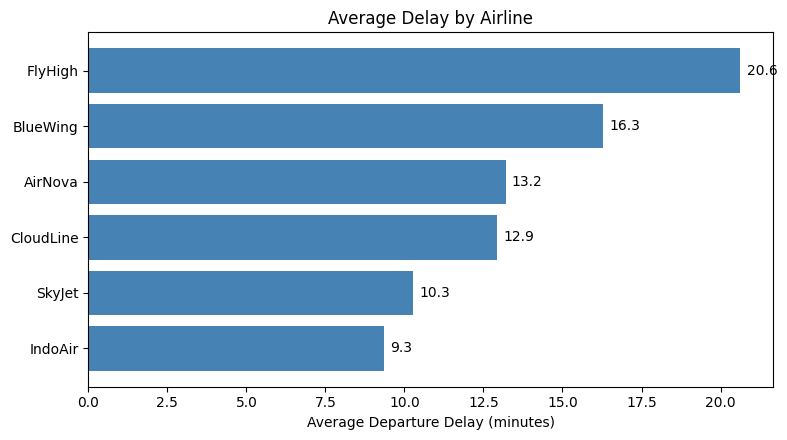

In [55]:
data = airline_summary['Avg_Delay_min'].sort_values()
plt.figure(figsize=(8, 4.5))
plt.barh(data.index, data.values, color='steelblue')
plt.xlabel('Average Departure Delay (minutes)')
plt.title('Average Delay by Airline')
for i, v in enumerate(data.values):
    plt.text(v + 0.2, i, str(round(v, 1)), va='center')
plt.tight_layout()
plt.show()

### Chart 2: Average Delay by Scheduled Hour of the Day

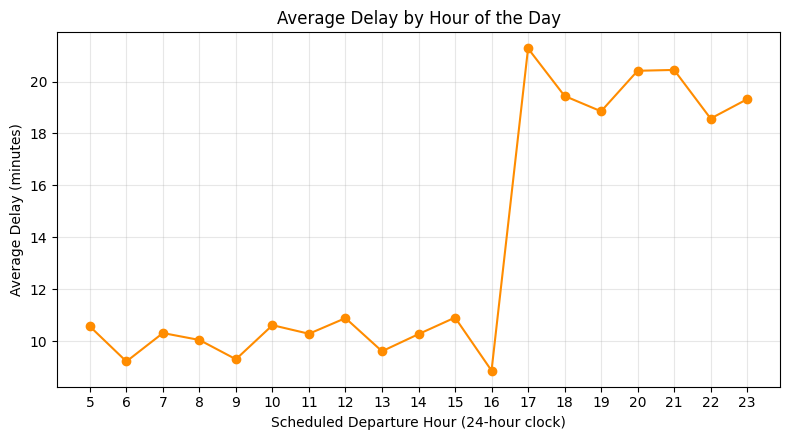

In [56]:
hourly = df_flown.groupby('Scheduled_Hour')['Departure_Delay_min'].mean()
plt.figure(figsize=(8, 4.5))
plt.plot(hourly.index, hourly.values, marker='o', color='darkorange')
plt.xlabel('Scheduled Departure Hour (24-hour clock)')
plt.ylabel('Average Delay (minutes)')
plt.title('Average Delay by Hour of the Day')
plt.xticks(range(5, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Chart 3: Average Delay by Month

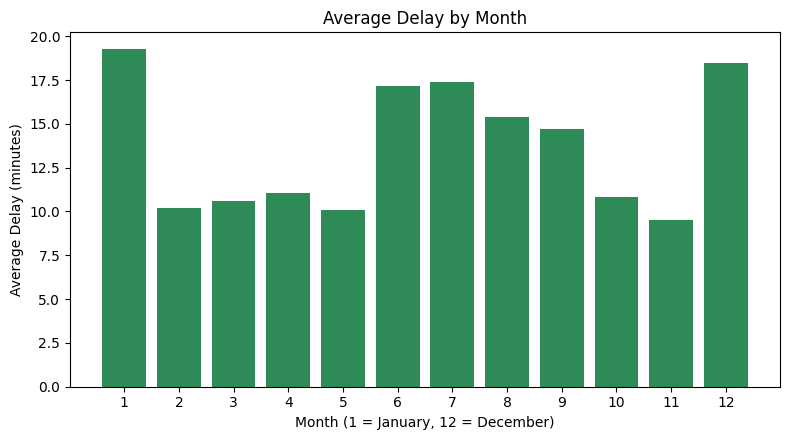

In [57]:
plt.figure(figsize=(8, 4.5))
plt.bar(month_summary.index, month_summary.values, color='seagreen')
plt.xlabel('Month (1 = January, 12 = December)')
plt.ylabel('Average Delay (minutes)')
plt.title('Average Delay by Month')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

### Chart 4: Reasons for Delay (Pie Chart)

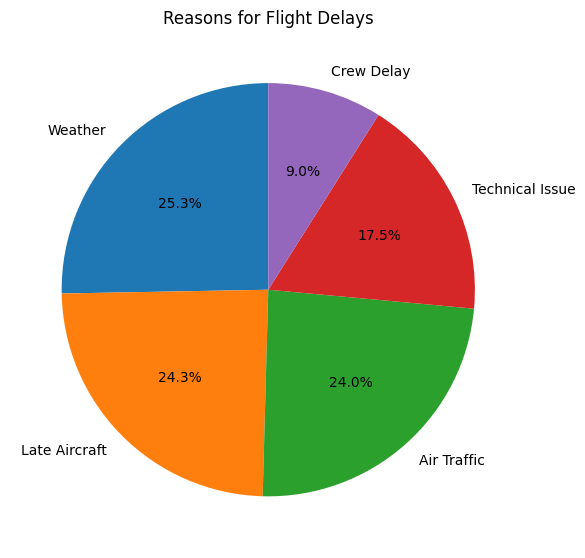

In [58]:
plt.figure(figsize=(6, 6))
plt.pie(reason_counts.values, labels=reason_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Reasons for Flight Delays')
plt.tight_layout()
plt.show()

### Chart 5: Distribution of Delays (Histogram)

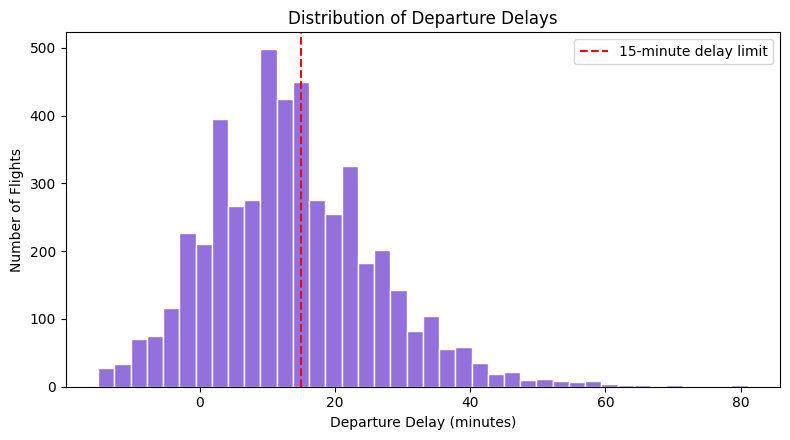

In [59]:
plt.figure(figsize=(8, 4.5))
plt.hist(df_flown['Departure_Delay_min'], bins=40, color='mediumpurple', edgecolor='white')
plt.axvline(15, color='red', linestyle='--', label='15-minute delay limit')
plt.xlabel('Departure Delay (minutes)')
plt.ylabel('Number of Flights')
plt.title('Distribution of Departure Delays')
plt.legend()
plt.tight_layout()
plt.show()

### Chart 6: Percentage of Delayed Flights by Origin Airport

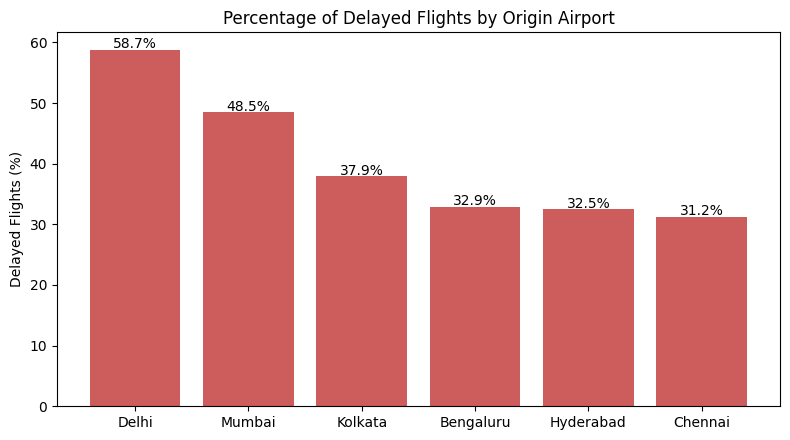

In [60]:
data = origin_summary['Delayed_Percent'].sort_values(ascending=False)
plt.figure(figsize=(8, 4.5))
plt.bar(data.index, data.values, color='indianred')
plt.ylabel('Delayed Flights (%)')
plt.title('Percentage of Delayed Flights by Origin Airport')
for i, v in enumerate(data.values):
    plt.text(i, v + 0.3, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.show()

## Step 8: Save the Cleaned Data

In [61]:
df_flown.to_csv('flight_delays_cleaned.csv', index=False)
print("Cleaned data saved as 'flight_delays_cleaned.csv'  (check the Files panel on the left in Colab)")

# Uncomment the lines below to download the file from Colab to your computer
# from google.colab import files
# files.download('flight_delays_cleaned.csv')

Cleaned data saved as 'flight_delays_cleaned.csv'  (check the Files panel on the left in Colab)


## Step 9: Key Findings

In [62]:
worst_airline = airline_summary['Avg_Delay_min'].idxmax()
best_airline  = airline_summary['Avg_Delay_min'].idxmin()
worst_origin  = origin_summary['Avg_Delay_min'].idxmax()
worst_time    = time_summary['Avg_Delay_min'].idxmax()
worst_season  = season_summary['Avg_Delay_min'].idxmax()
top_reason    = reason_counts.idxmax()

print("=" * 55)
print("          KEY FINDINGS OF THE PROJECT")
print("=" * 55)
print(f"1. Overall delayed flights      : {df_flown['Is_Delayed'].mean()*100:.1f}%")
print(f"2. Average delay                : {df_flown['Departure_Delay_min'].mean():.1f} minutes")
print(f"3. Most delayed airline         : {worst_airline}")
print(f"4. Least delayed airline        : {best_airline}")
print(f"5. Most delayed origin airport  : {worst_origin}")
print(f"6. Worst time of day            : {worst_time}")
print(f"7. Worst season                 : {worst_season}")
print(f"8. Most common delay reason     : {top_reason}")
print("=" * 55)

          KEY FINDINGS OF THE PROJECT
1. Overall delayed flights      : 40.2%
2. Average delay                : 13.8 minutes
3. Most delayed airline         : FlyHigh
4. Least delayed airline        : IndoAir
5. Most delayed origin airport  : Delhi
6. Worst time of day            : Evening (17-20)
7. Worst season                 : Winter
8. Most common delay reason     : Weather


## ✅ Conclusion
In this project we used **Python, NumPy and Pandas** to clean and analyse airline flight-delay data.  
We found that delays are strongly connected to the **time of day, the season, the airline and the origin airport**,
while **flight distance has almost no effect** on delay.

**What we learned:** loading data, checking missing values, removing duplicates, creating new columns,
`groupby`, `pivot_table`, NumPy statistics and plotting charts with Matplotlib.

**Future improvements:** use a real airline dataset, add arrival delay and weather data, and build a simple prediction model (Machine Learning).

---
*Project by Lakshya Tripathi – B.Tech 1st Year*